# 12 — CHIRPS Spatial Buffer Experiment (v2 and v3 RNL)

**Research question:** Does averaging CHIRPS rainfall over a fixed 5 km or 10 km radius around a rain gauge improve agreement compared with extracting the grid-cell value at the gauge location?

**Design:** CHIRPS v2 and v3 RNL; six stations; 1981–2000. Primary measures daily paired Pearson/Spearman, bias, MAE and RMSE. Secondary measures complete pentad and calendar-month totals, and heavy rainfall. Compare **exact same gauge-date pairs** for point/5km/10km methods. Don't tune a radius on final test data.

Run Google Earth Engine script `11_CHIRPS_Buffered_Extraction_GEE.js` first, exporting each year (1981–2000) for each version into one folder. Copy the exported CSVs into `data/chirps/buffered/`. Do not assume a buffer helps; it may smooth heavy rainfall.


## 1. Project directories and imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

here=Path.cwd().resolve()
PROJECT_DIR=next((p for p in (here,here.parent) if (p/'data'/'processed').is_dir()),here.parent)
PROCESSED_DIR=PROJECT_DIR/'data'/'processed'
BUFFER_DIR=PROJECT_DIR/'data'/'chirps'/'buffered'
RESULTS_DIR=PROJECT_DIR/'results'/'Buffered_Satellite_Extraction'
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
print('Buffer CSV directory:',BUFFER_DIR)
print('Output directory:',RESULTS_DIR)


Buffer CSV directory: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\chirps\buffered
Output directory: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Buffered_Satellite_Extraction


## 2. Load buffered GEE data and gauge records
This requires real GEE exports. A clear error will appear if you have not exported them yet.

In [9]:
from glob import glob
VERSION='v2' # change to 'v3rnl' after running v2
files=sorted(BUFFER_DIR.glob(f'CHIRPS_Buffer_{VERSION}_*.csv'))
if not files:
    raise FileNotFoundError(f'No buffer exports in {BUFFER_DIR}. Run the included GEE JS script first.')
raw=pd.concat((pd.read_csv(p) for p in files),ignore_index=True)
raw['Date']=pd.to_datetime(raw['Date'],errors='coerce')
raw['Station']=raw['Station'].replace({'Nuwaraeliya':'Nuwara Eliya'})
cols=['Point_mm','Buffer5km_mm','Buffer10km_mm']
for x in cols:raw[x]=pd.to_numeric(raw[x],errors='coerce')
raw=raw.dropna(subset=['Date','Station']).copy()
if raw.duplicated(['Station','Date']).any():
    raise ValueError('Duplicate station/date pairs: check year exports before proceeding')
# The notebook 03 file includes both CHIRPS and ground rainfall.
gauge_file=PROCESSED_DIR/'Ground_CHIRPS_Paired_1981_2000.csv'
if not gauge_file.exists():raise FileNotFoundError(gauge_file)
gauge=pd.read_csv(gauge_file,usecols=['Station','Date','Rainfall_mm'])
gauge['Date']=pd.to_datetime(gauge['Date'])
gauge['Station']=gauge['Station'].replace({'Nuwaraeliya':'Nuwara Eliya'})
gauge['Rainfall_mm']=pd.to_numeric(gauge['Rainfall_mm'],errors='coerce')
if gauge.duplicated(['Station','Date']).any():raise ValueError('Duplicate dates in gauge file')
paired=raw.merge(gauge,on=['Station','Date'],how='inner',validate='one_to_one')
paired=paired.dropna(subset=['Rainfall_mm']+cols).copy()
paired=paired[(paired['Rainfall_mm']>=0)&(paired[cols].ge(0).all(axis=1))]
paired=paired.sort_values(['Station','Date']).reset_index(drop=True)
print('Paired rows:',len(paired),'| stations:',paired.Station.nunique())
display(paired.groupby('Station').agg(Days=('Date','size'),Start=('Date','min'),End=('Date','max')))


Paired rows: 43737 | stations: 6


,Days,Start,End
Station,,,
Badulla,7300,1981-01-01,2000-12-31
Colombo,7279,1981-01-01,2000-12-31
Galle,7291,1981-01-01,2000-12-31
Kandy,7296,1981-01-01,2000-12-31
Nuwara Eliya,7278,1981-01-01,2000-12-31
Puttalam,7293,1981-01-01,2000-12-31


## 3. Compute daily scores for a fixed evaluation period
For unbiased comparisons, use 1995–2000 as an evaluation period, but do not use it to pick the buffer radius and then claim it was untouched. Raw same-day point and buffer fields are compared on exactly the same rows.

In [11]:
def calculate(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);err=p-y
    from scipy.stats import spearmanr
    return {'Bias':np.mean(err),'MAE':np.mean(abs(err)),
            'RMSE':np.sqrt(np.mean(err**2)),
            'Pearson':np.corrcoef(y,p)[0,1] if np.std(y)>0 and np.std(p)>0 else np.nan,
            'Spearman':spearmanr(y,p).statistic if np.std(y)>0 and np.std(p)>0 else np.nan}

eval_df=paired.loc[paired.Date.between('1995-01-01','2000-12-31')].copy()
if eval_df.empty:raise ValueError('No 1995–2000 dates present')
rows=[]
for st,d in eval_df.groupby('Station'):
    for method in cols:rows.append({'Station':st,'Method':method,'Days':len(d),**calculate(d.Rainfall_mm,d[method])})
daily_scores=pd.DataFrame(rows)
display(daily_scores.round(3))


,Station,Method,Days,Bias,MAE,RMSE,Pearson,Spearman
0,Badulla,Point_mm,2191,0.589,5.531,11.297,0.387,0.443
1,Badulla,Buffer5km_mm,2191,0.976,5.715,11.501,0.397,0.463
2,Badulla,Buffer10km_mm,2191,1.276,5.850,11.599,0.403,0.479
3,Colombo,Point_mm,2191,-0.386,7.539,16.207,0.369,0.468
4,Colombo,Buffer5km_mm,2191,-0.217,7.495,16.035,0.382,0.492
5,Colombo,Buffer10km_mm,2191,0.062,7.582,16.050,0.386,0.501
6,Galle,Point_mm,2192,-0.688,7.241,15.223,0.433,0.398
7,Galle,Buffer5km_mm,2192,-0.241,7.333,15.294,0.444,0.427
8,Galle,Buffer10km_mm,2192,0.119,7.461,15.540,0.443,0.432
9,Kandy,Point_mm,2190,0.711,6.487,12.776,0.334,0.394


## 4. Daily scatter plots with 1:1 agreement line

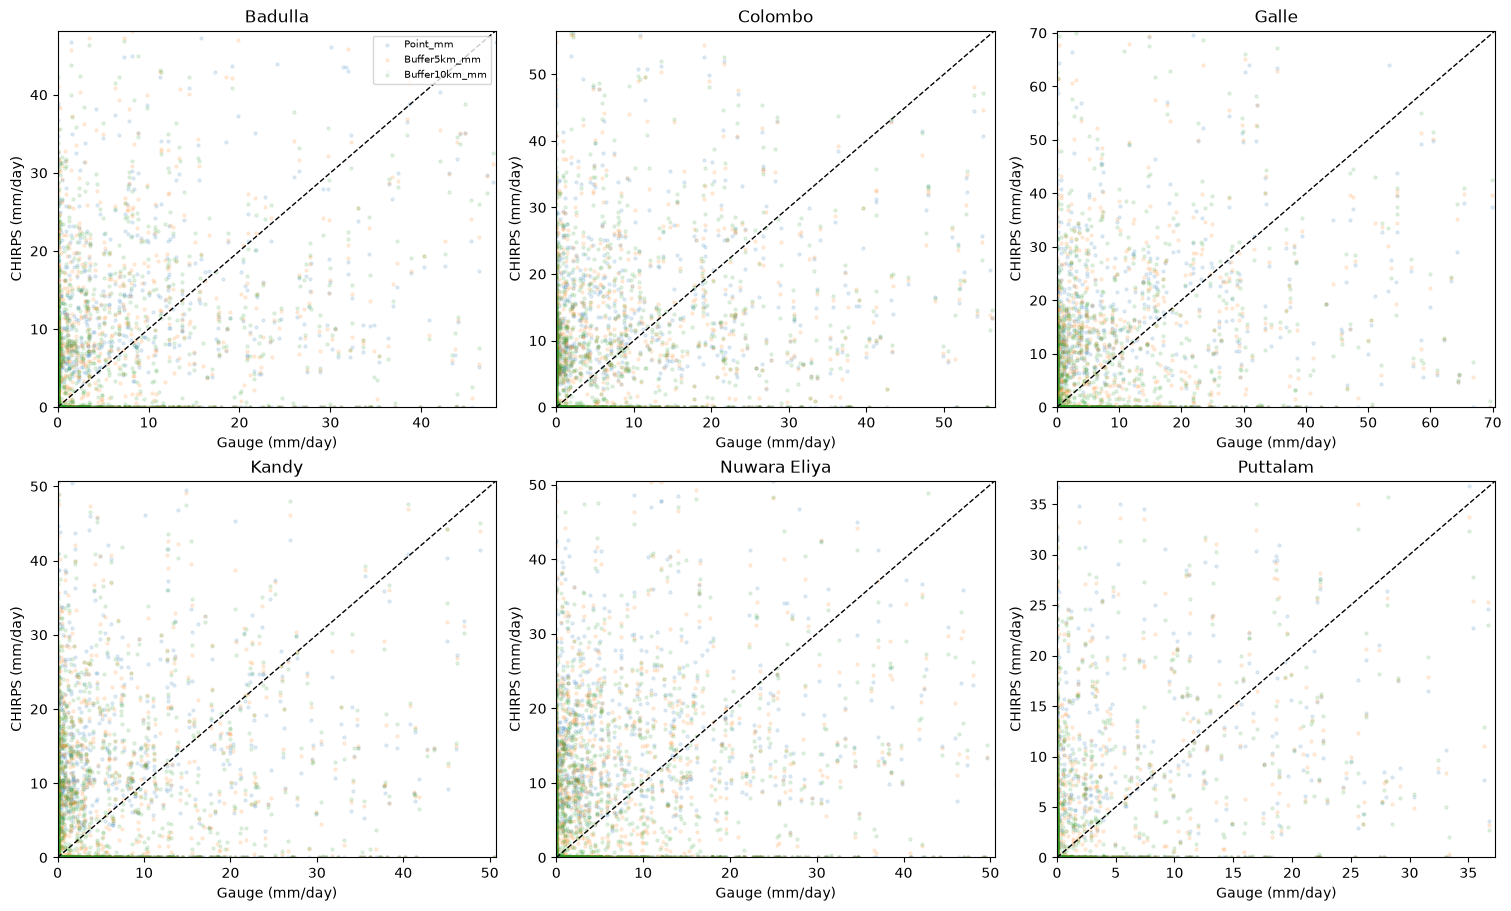

In [13]:
stations=sorted(eval_df.Station.unique())
fig,axes=plt.subplots(2,3,figsize=(15,9),constrained_layout=True)
for ax,st in zip(axes.flat,stations):
    d=eval_df[eval_df.Station.eq(st)]
    upper=np.quantile(np.r_[d.Rainfall_mm.to_numpy(),d[cols].to_numpy().ravel()],0.99)
    for method in cols:ax.scatter(d.Rainfall_mm,d[method],s=5,alpha=.12,label=method)
    ax.plot([0,upper],[0,upper],'k--',lw=1)
    ax.set(xlim=(0,upper),ylim=(0,upper),title=st,xlabel='Gauge (mm/day)',ylabel='CHIRPS (mm/day)')
axes.flat[0].legend(fontsize=7)
plt.show()


## 5. Monthly and pentad totals, complete periods only
Pentads align to CHIRPS calendar-day groups (1–5, 6–10, ..., 26–end-of-month). No partial period is treated as a full total.

In [15]:
def aggregate_complete(d,scale):
    x=d.copy()
    if scale=='month':
        x['Period']=x.Date.dt.to_period('M').dt.start_time
        x['Expected']=x.Date.dt.days_in_month
    elif scale=='pentad':
        x['Pentad']=np.minimum((x.Date.dt.day-1)//5,5)
        x['Period']=x.Date.dt.to_period('M').dt.start_time+pd.to_timedelta(x.Pentad*5,unit='D')
        x['Expected']=np.where(x.Pentad.eq(5),x.Date.dt.days_in_month-25,5)
    else:raise ValueError(scale)
    agg=x.groupby(['Station','Period'],as_index=False).agg(
        Days=('Date','nunique'),Expected=('Expected','first'),
        Gauge=('Rainfall_mm','sum'),**{k:(k,'sum') for k in cols})
    return agg[agg.Days.eq(agg.Expected)].copy()

agg_tables={};summary=[]
for scale in ['pentad','month']:
    d=aggregate_complete(eval_df,scale)
    agg_tables[scale]=d
    for st,x in d.groupby('Station'):
        for method in cols:
            summary.append({'Scale':scale,'Station':st,'Method':method,'Periods':len(x),
                            **calculate(x.Gauge,x[method])})
agg_scores=pd.DataFrame(summary)
display(agg_scores.round(3))


,Scale,Station,Method,Periods,Bias,MAE,RMSE,Pearson,Spearman
0,pentad,Badulla,Point_mm,431,2.994,17.443,25.709,0.650,0.593
1,pentad,Badulla,Buffer5km_mm,431,4.959,18.113,26.471,0.655,0.598
2,pentad,Badulla,Buffer10km_mm,431,6.480,18.869,27.394,0.649,0.596
3,pentad,Colombo,Point_mm,431,-1.897,23.941,37.561,0.648,0.662
4,pentad,Colombo,Buffer5km_mm,431,-1.031,23.797,37.429,0.652,0.677
5,pentad,Colombo,Buffer10km_mm,431,0.379,24.145,37.533,0.652,0.675
6,pentad,Galle,Point_mm,432,-3.489,23.687,38.245,0.595,0.623
7,pentad,Galle,Buffer5km_mm,432,-1.223,24.010,39.164,0.593,0.641
8,pentad,Galle,Buffer10km_mm,432,0.606,24.684,40.488,0.583,0.645
9,pentad,Kandy,Point_mm,430,3.735,21.307,31.528,0.547,0.568


## 6. Visualize which buffer is better
A small change may not be robust. Inspect both overall RMSE and heavy-rainfall bias before drawing a conclusion.

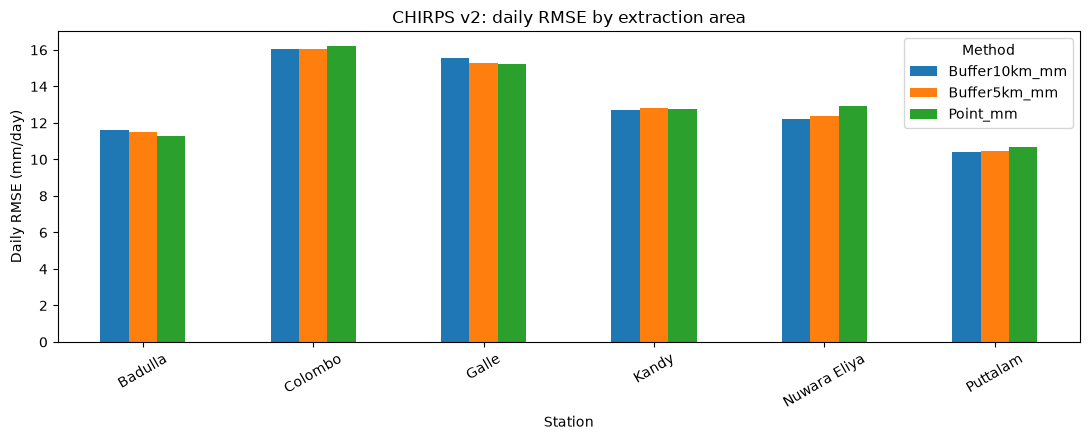

,Station,Method,Heavy_Days,Bias,MAE,RMSE,Pearson,Spearman
0,Badulla,Point_mm,121,-24.077,26.866,31.897,0.172,0.134
1,Badulla,Buffer5km_mm,121,-22.753,26.658,31.481,0.171,0.124
2,Badulla,Buffer10km_mm,121,-21.972,26.388,31.123,0.176,0.132
3,Colombo,Point_mm,169,-33.626,36.331,46.815,0.203,0.301
4,Colombo,Buffer5km_mm,169,-33.258,35.926,46.286,0.219,0.324
5,Colombo,Buffer10km_mm,169,-32.742,35.527,45.749,0.231,0.335
6,Galle,Point_mm,160,-27.077,34.267,42.600,0.222,0.221
7,Galle,Buffer5km_mm,160,-25.605,33.725,42.167,0.225,0.232
8,Galle,Buffer10km_mm,160,-24.446,33.392,42.282,0.206,0.220
9,Kandy,Point_mm,115,-28.678,29.908,34.748,0.413,0.222


In [17]:
pivot=daily_scores.pivot(index='Station',columns='Method',values='RMSE')
pivot.plot(kind='bar',figsize=(11,4.5),title=f'CHIRPS {VERSION}: daily RMSE by extraction area')
plt.ylabel('Daily RMSE (mm/day)');plt.xticks(rotation=30);plt.tight_layout();plt.show()
heavy=[]
for st,d in eval_df.groupby('Station'):
    x=d[d.Rainfall_mm>25]
    if x.empty:continue
    for method in cols:heavy.append({'Station':st,'Method':method,'Heavy_Days':len(x),**calculate(x.Rainfall_mm,x[method])})
heavy_scores=pd.DataFrame(heavy)
display(heavy_scores.round(3))


## 7. Save results and write up responsibly

In [19]:
prefix=f'buffer_{VERSION}'
paired.to_csv(RESULTS_DIR/f'{prefix}_paired_data.csv',index=False)
daily_scores.to_csv(RESULTS_DIR/f'{prefix}_daily_scores.csv',index=False)
agg_scores.to_csv(RESULTS_DIR/f'{prefix}_pentad_monthly_scores.csv',index=False)
heavy_scores.to_csv(RESULTS_DIR/f'{prefix}_heavy_scores.csv',index=False)
print('Saved results to:',RESULTS_DIR)


Saved results to: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Buffered_Satellite_Extraction


### Research report text (edit after results)

*We evaluated spatial representativeness by extracting daily CHIRPS v2 and v3 RNL at each rain-gauge point and averaging raster precipitation within 5 km and 10 km circular buffers. All three methods were compared against the same observed station-day pairs. Monthly and CHIRPS-aligned pentad totals were calculated only for complete periods. The buffer study tests whether neighbourhood averaging improves gauge agreement, rather than presuming that larger spatial support is more accurate. Spatial smoothing can reduce isolated errors but can also obscure localized extremes. Buffer radius was not selected using final test observations.*

**Limitations:** 0.05° grid; pixel-to-point representativeness; buffer averages are areal estimates, not gauge measurements; rain shadows and elevation gradients can make averaging worse; coordinate/date conventions; only six stations; possible CHIRPS gauge blending. Reference: Funk et al. (2015), https://doi.org/10.1038/sdata.2015.66; CHIRPS Earth Engine dataset catalogues.
